# Noisy Double-Well Transition Path Sampling

This notebook conditions a **stochastic process** rather than a Gaussian process: latent Gaussian increments are pushed through an overdamped Langevin simulator, and guidance conditions the resulting paths on a rare transition event. It reproduces the synthetic double-well experiment of Seong et al., *Transition Path Sampling with Improved Off-Policy Training of Diffusion Path Samplers* (TPS-DPS, ICLR 2025), in which a particle follows

$$dR_t = -\nabla U(R_t)\,dt + \sqrt{2\gamma k_B \lambda}\;dW_t$$

in a 2D potential with two wells connected by two reaction channels. Unbiased simulation almost never crosses between the wells; instead of *training* a bias force as TPS-DPS does, we condition the unbiased path measure on reaching the target well with Monte-Carlo guidance, and recover diverse transition paths through **both** channels.

## 1. Imports

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch

from flow_inference.conditions import EqualityCondition
from flow_inference.flows import GaussianIncrementFlow
from flow_inference.guidance import GuidanceMC
from flow_inference.maps import BaseMap
from flow_inference.sampler import IntegratorSampler

torch.set_default_dtype(torch.float64)

## 2. Configuration

The physical constants are taken verbatim from the TPS-DPS paper (Appendix B.4) and its reference implementation: $\Delta t = 0.01$, $T = 10$ (1000 MD steps), temperature $\lambda = 1200\,\mathrm{K}$ and $k_B = 8.6173303\times 10^{-5}$, giving a per-step noise standard deviation $\sqrt{2 k_B \lambda\, \Delta t} \approx 0.045$.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)  # reproducible runs

num_samples = 100  # paths per prior / guided batch
kB = 8.6173303e-5  # Boltzmann constant (paper's reduced units)
temperature = 1200.0  # lambda, in K
dt_md = 0.01  # MD step size
num_md_steps = 1000  # T / dt = 10 / 0.01
noise_std = math.sqrt(2.0 * kB * temperature * dt_md)  # per-step Brownian std (~0.045)

R_A = torch.tensor([-1.118, 0.0], device=device)  # initial meta-stable state (left minimum)
R_B = torch.tensor([1.118, 0.0], device=device)  # target meta-stable state (right minimum)

## 3. The Double-Well SDE

The potential (paper Eq. 46) is

$$U(x, y) = \tfrac{1}{6}\Big[\,4(1 - x^2 - y^2)^2 + 2(x^2 - 2)^2 + \big((x+y)^2 - 1\big)^2 + \big((x-y)^2 - 1\big)^2 - 2\,\Big],$$

with two global minima $R_\mathcal{A} = (-1.118, 0)$ and $R_\mathcal{B} = (+1.118, 0)$ and two saddle points at $(0, \pm 1)$, one per reaction channel. `DoubleWellDualChannelMap` integrates the Langevin SDE (paper Eq. 45, $\gamma = m = 1$) with Euler-Maruyama. The $(x, y)$ channels are coupled coordinates of one particle, so the map overrides `_map` and consumes the whole `(B, 2, num_md_steps)` tensor of Brownian increments; the particle starts deterministically at $R_\mathcal{A}$, so each path has `num_md_steps + 1` positions.

In [3]:
def double_well_potential(xy: torch.Tensor) -> torch.Tensor:
    """Paper Eq. 46 potential. xy: (..., 2) -> (...,) energy."""
    x, y = xy[..., 0], xy[..., 1]
    term_1 = 4.0 * (1.0 - x**2 - y**2) ** 2
    term_2 = 2.0 * (x**2 - 2.0) ** 2
    term_3 = ((x + y) ** 2 - 1.0) ** 2
    term_4 = ((x - y) ** 2 - 1.0) ** 2
    return (term_1 + term_2 + term_3 + term_4 - 2.0) / 6.0


def double_well_force(xy: torch.Tensor) -> torch.Tensor:
    """Analytic force -grad U. xy: (..., 2) -> (..., 2)."""
    x, y = xy[..., 0], xy[..., 1]
    a = 1.0 - x**2 - y**2
    b = x**2 - 2.0
    c = (x + y) ** 2 - 1.0
    d = (x - y) ** 2 - 1.0
    grad_x = (-16.0 * a * x + 8.0 * b * x + 4.0 * c * (x + y) + 4.0 * d * (x - y)) / 6.0
    grad_y = (-16.0 * a * y + 4.0 * c * (x + y) - 4.0 * d * (x - y)) / 6.0
    return -torch.stack([grad_x, grad_y], dim=-1)


def double_well_step_fn(xy: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
    """One Euler-Maruyama step of dR = -grad U dt + sqrt(2 kB lambda) dW."""
    return xy + double_well_force(xy) * dt_md + noise_std * noise


class DoubleWellDualChannelMap(BaseMap):
    """Coupled (x, y) Euler-Maruyama simulator launched from R_A."""

    def __init__(self, num_steps: int = num_md_steps):
        super().__init__(
            latent_dim=num_steps,
            output_shape=(num_steps + 1,),
            channels=2,
            device=device,
            dtype=torch.float64,
        )
        self.num_steps = num_steps
        self.register_buffer("R_A", R_A.clone())

    def _map(self, z: torch.Tensor) -> torch.Tensor:
        """z: (B, 2, num_steps) iid N(0, 1) -> (B, 2, num_steps + 1) (x, y) paths."""
        B, C, L = z.shape
        if C != 2 or L != self.num_steps:
            raise ValueError(f"expected latent shape (B, 2, {self.num_steps}), got {tuple(z.shape)}")
        noises = z.permute(0, 2, 1)  # (B, num_steps, 2)
        xy = self.R_A[None, :].expand(B, 2)
        path = [xy]
        for k in range(self.num_steps):
            xy = double_well_step_fn(xy, noises[:, k])
            path.append(xy)
        return torch.stack(path, dim=-1)  # (B, 2, num_steps + 1)

## 4. Prior Samples

We score paths with the three TPS-DPS metrics, each computed on the path truncated at its closest approach to $R_\mathcal{B}$ (as in the reference implementation):
- **THP** (target hit percentage): % of paths whose closest approach lies inside $\mathcal{B} = \{R : \lVert R - R_\mathcal{B}\rVert < 0.5\}$.
- **RMSD**: distance from the closest approach to $R_\mathcal{B}$, averaged over all paths.
- **ETS** (energy of the transition state): highest potential crossed before the closest approach, averaged over hitting paths (paper: $\approx 1.4$–$1.7$, vs. saddle energy $U = 1.0$).

In [4]:
def plot_on_landscape(samples, num_paths=64, title=None):
    """Draw (B, 2, L) paths over filled contours of U (cf. paper Figure 4, top row)."""
    xy = samples.detach().cpu().numpy()
    fig, ax = plt.subplots(figsize=(6, 6))
    X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
    Z = double_well_potential(torch.from_numpy(np.stack([X, Y], -1))).numpy()
    ax.contourf(X, Y, Z, levels=100, vmax=3, zorder=0)
    cmap = plt.get_cmap("gist_rainbow")
    for i in range(min(num_paths, xy.shape[0])):
        ax.plot(xy[i, 0], xy[i, 1], color=cmap(i / num_paths), lw=0.6, alpha=0.6, zorder=1)
    ax.scatter([-1.118, 1.118], [0.0, 0.0], c="w", edgecolors="k", s=300, zorder=3)  # wells A, B
    ax.scatter([0.0, 0.0], [1.0, -1.0], c="w", edgecolors="k", marker="*", s=400, zorder=3)  # saddles
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    return ax


def transition_path_metrics(samples):
    """THP, RMSD and ETS, each read at the path's closest approach to R_B."""
    path = samples.permute(0, 2, 1)  # (B, L, 2)
    dist = torch.linalg.norm(path - R_B[None, None, :], dim=-1)  # (B, L)
    rmsd, hit_idx = dist.min(dim=-1)  # closest approach
    hit = rmsd < 0.5
    energy = double_well_potential(path)  # (B, L)
    steps = torch.arange(path.shape[1], device=samples.device)[None, :]
    ets = energy.masked_fill(steps > hit_idx[:, None], float("-inf")).max(dim=-1).values[hit]
    return {
        "THP": 100.0 * hit.float().mean().item(),
        "RMSD": (rmsd.mean().item(), rmsd.std().item()),
        "ETS": (ets.mean().item(), ets.std().item()) if hit.any() else (float("nan"), float("nan")),
        "n_hit": int(hit.sum().item()),
    }


def print_metrics(samples, label):
    m = transition_path_metrics(samples)
    ets = f"{m['ETS'][0]:.2f} ± {m['ETS'][1]:.2f}" if m["n_hit"] else "-"
    print(f"{label:>26}:  THP {m['THP']:5.1f}%   RMSD {m['RMSD'][0]:.3f} ± {m['RMSD'][1]:.3f}   ETS {ets}")

`GaussianIncrementFlow` runs the flow over the iid Gaussian increments and pushes them through the map, so sampling it without guidance gives unbiased MD paths. As with UMD at 1200 K in the paper, the particle stays trapped in the left well (THP $\approx 0$): spontaneous crossings are exponentially rare.

  0%|          | 0/1 [00:00<?, ?it/s]

         unbiased MD prior:  THP   0.0%   RMSD 1.902 ± 0.060   ETS -


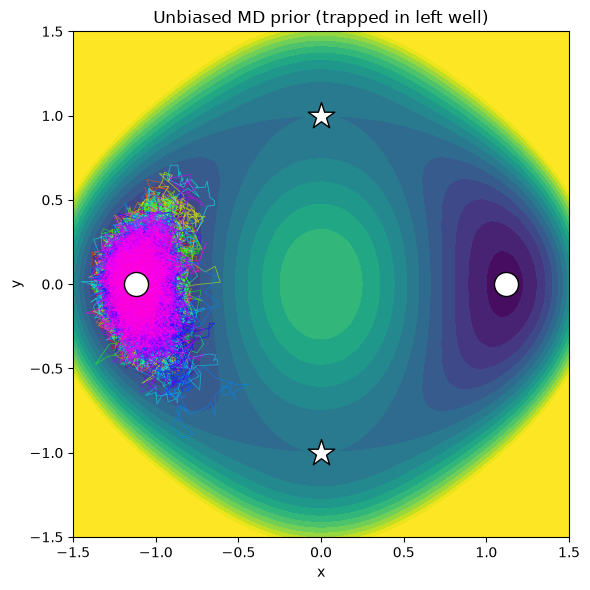

In [5]:
flow = GaussianIncrementFlow(map=DoubleWellDualChannelMap(), device=device)
sampler = IntegratorSampler(flow=flow)
prior_samples = sampler.sample(num_samples, num_steps=2).detach()

print_metrics(prior_samples, "unbiased MD prior")
plot_on_landscape(prior_samples, title="Unbiased MD prior (trapped in left well)");

## 5. Condition on the Transition Event

To turn the trapped prior into transition paths, condition on the particle **reaching** $\mathcal{B}$ at some point along its path. `TransitionPathEvent` is an `EqualityCondition` whose residual is a soft minimum over time of the distance to $R_\mathcal{B}$, mirroring the max-over-path relaxed indicator used as the TPS-DPS training reward. Guidance uses the SDE sampler; `max_norm` softly limits the guidance magnitude and trades THP against ETS (lower it for smoother, lower-ETS paths at the cost of hit rate).

  0%|          | 0/24 [00:00<?, ?it/s]

         unbiased MD prior:  THP   0.0%   RMSD 1.902 ± 0.060   ETS -
        guided (TPS event):  THP  96.0%   RMSD 0.033 ± 0.152   ETS 1.53 ± 0.33


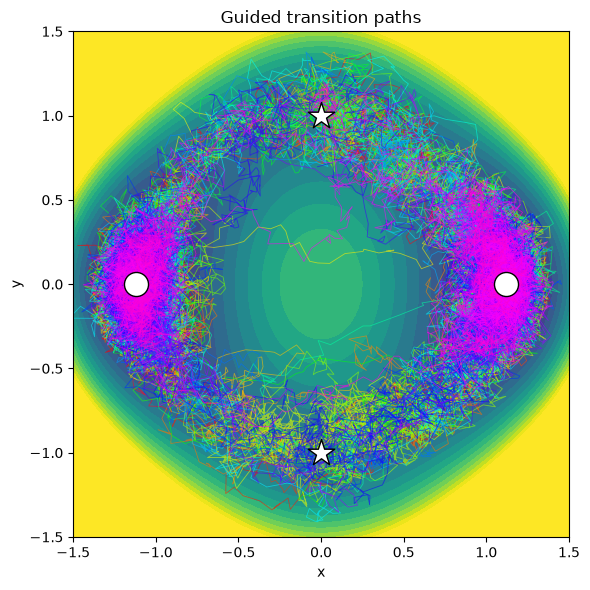

In [6]:
class TransitionPathEvent(EqualityCondition):
    def __init__(self, sigma: float = 1e-1, beta: float = 1_000.0):
        super().__init__(sigma=sigma)
        self.beta = beta  # softmin sharpness; beta -> inf recovers the hard min
        self.register_buffer("R_B", R_B.clone())

    def residual(self, x: torch.Tensor) -> torch.Tensor:
        dist = torch.linalg.norm(x - self.R_B[None, :, None], dim=1)  # (B, L)
        # Soft min spreads the gradient over every step (weights softmax(-beta * dist)),
        # unlike a hard min, which only reaches the single closest step.
        closest = -torch.logsumexp(-self.beta * dist, dim=-1) / self.beta  # (B,)
        return closest[:, None, None]


condition = TransitionPathEvent(sigma=1e-5)
guidance = GuidanceMC(flow, condition, num_mc_samples=1, max_norm=1e1).to(device)
samples = sampler.sample(num_samples, guidance=guidance, num_steps=25, sde=True).detach()

print_metrics(prior_samples, "unbiased MD prior")
print_metrics(samples, "guided (TPS event)")
plot_on_landscape(samples, title="Guided transition paths");